# Pashto Topic Classification — 3 Classic ML Algorithms

This notebook trains and compares **three machine-learning algorithms** on the **Pashto Topic Classification Dataset** — 27,437 news paragraphs in Pashto, labeled with 12 topics, collected from five Pashto news outlets.

**Dataset highlights**
- Paragraph-level text, kept exactly as published (authentic Pashto orthography, ZWNJ preserved).
- 12 classes, each with an English label (`topic`) and a Pashto label (`topic_ps`).
- One clean CSV — we create a **stratified 80/10/10 train/val/test split** below (fixed `random_state` for reproducibility).

**Models trained here**
1. Logistic Regression
2. Linear Support Vector Machine (LinearSVC)
3. Multinomial Naive Bayes

Plus a tuning section at the end that pushes the best model further.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

BLUE = "#2a78d6"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

# Works on Kaggle (attach the dataset) and locally
candidates = list(Path("/kaggle/input").glob("*/")) if Path("/kaggle/input").exists() else []
DATA = next((p for p in candidates if (p / "train.csv").exists()), Path("output"))
print("Data directory:", DATA)

Data directory: output


## 1. Load the dataset and check it

In [2]:
df = pd.read_csv(DATA / "pashto_topic_dataset.csv")
print("full dataset:", df.shape)
df.head(3)

full dataset: (27437, 4)


,id,text,topic,topic_ps
0,1,هغه شيان چې له استهلاک پرته ورڅخه ګټه نشي اخيس...,economy,اقتصاد
1,2,"هغه زیاته کړه: ""زموږ مېوه خو چې وشکوو باید یا ...",agriculture,کرنه
2,3,په ورته وخت کې، نوموړي زیاته کړه چې هېوادوال د...,education,ښوونه او روزنه


In [3]:
# Integrity checks
print("missing values per column:")
print(df.isna().sum())
print("\nexact duplicate texts:", df["text"].duplicated().sum())
print("classes:", df["topic"].nunique())
print("\nEnglish <-> Pashto label mapping:")
print(df.groupby("topic")["topic_ps"].first())

missing values per column:
id          0
text        0
topic       0
topic_ps    0
dtype: int64

exact duplicate texts: 0
classes: 12

English <-> Pashto label mapping:
topic
agriculture                کرنه
economy                  اقتصاد
education        ښوونه او روزنه
entertainment      کلتور او هنر
environment            چاپېریال
health                   روغتیا
politics                  سیاست
religion                    دین
security                  امنیت
sports                     لوبې
technology             ټکنالوژي
world                       نړۍ
Name: topic_ps, dtype: str


words per paragraph: min=9  median=36  mean=40.0  max=121


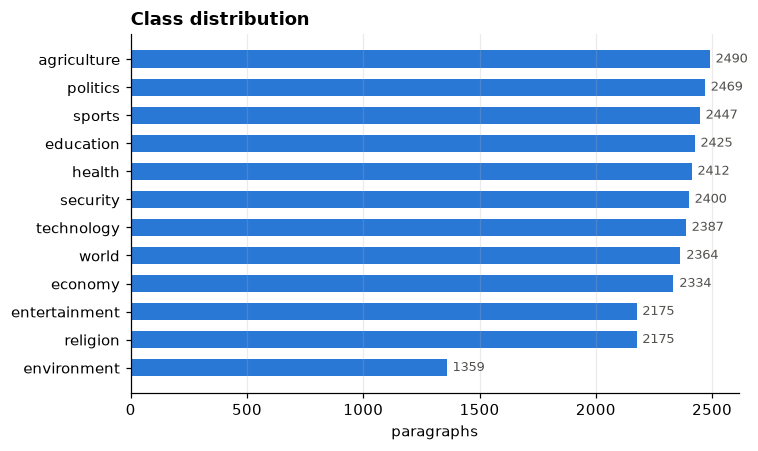

In [4]:
wc = df["text"].str.split().str.len()
print(f"words per paragraph: min={wc.min()}  median={wc.median():.0f}  mean={wc.mean():.1f}  max={wc.max()}")

counts = df["topic"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(counts.index, counts.values, color=BLUE, height=0.62)
for i, v in enumerate(counts.values):
    ax.text(v + 25, i, str(v), va="center", fontsize=8.5, color="#52514e")
ax.set_xlabel("paragraphs")
ax.set_title("Class distribution", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

The classes are well balanced, and macro-F1 is reported alongside accuracy so every class counts equally.

## 2. Stratified split and TF-IDF features

A stratified 80/10/10 split keeps every class at the same proportion in train, validation and test. Word uni+bigram TF-IDF is fitted on the training split only.

In [5]:
from sklearn.model_selection import train_test_split

train, tmp = train_test_split(df, test_size=0.20, stratify=df["topic"], random_state=42)
val, test = train_test_split(tmp, test_size=0.50, stratify=tmp["topic"], random_state=42)
print(f"train: {len(train)} | val: {len(val)} | test: {len(test)}")
print("\ntest-split class proportions match the full dataset:")
print(pd.concat([df["topic"].value_counts(normalize=True).rename("full"),
                 test["topic"].value_counts(normalize=True).rename("test")], axis=1).round(3))

train: 21949 | val: 2744 | test: 2744

test-split class proportions match the full dataset:
                full   test
topic                      
agriculture    0.091  0.091
politics       0.090  0.090
sports         0.089  0.089
education      0.088  0.088
health         0.088  0.088
security       0.087  0.087
technology     0.087  0.087
world          0.086  0.086
economy        0.085  0.085
religion       0.079  0.079
entertainment  0.079  0.079
environment    0.050  0.050


In [6]:
vec = TfidfVectorizer(ngram_range=(1, 2), max_features=120_000, sublinear_tf=True)
Xtr = vec.fit_transform(train["text"]); ytr = train["topic"]
Xva = vec.transform(val["text"]);      yva = val["topic"]
Xte = vec.transform(test["text"]);     yte = test["topic"]
print("vocabulary size:", len(vec.vocabulary_))

vocabulary size: 120000


## 3. Train the three models

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=4),
    "Linear SVM": LinearSVC(C=0.5),
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.3),
}
results = {}
for name, model in models.items():
    model.fit(Xtr, ytr)
    pv, pt = model.predict(Xva), model.predict(Xte)
    results[name] = {
        "val acc": accuracy_score(yva, pv),
        "test acc": accuracy_score(yte, pt),
        "test macro-F1": f1_score(yte, pt, average="macro"),
        "pred": pt,
    }
    print(f"{name:26s} val acc {results[name]['val acc']:.4f} | "
          f"test acc {results[name]['test acc']:.4f} | test macro-F1 {results[name]['test macro-F1']:.4f}")

Logistic Regression        val acc 0.8127 | test acc 0.8123 | test macro-F1 0.8119


Linear SVM                 val acc 0.8309 | test acc 0.8324 | test macro-F1 0.8311
Multinomial Naive Bayes    val acc 0.7773 | test acc 0.7741 | test macro-F1 0.7668


In [8]:
comparison = pd.DataFrame(results).T.drop(columns="pred").astype(float).round(4)
comparison

,val acc,test acc,test macro-F1
Logistic Regression,0.8127,0.8123,0.8119
Linear SVM,0.8309,0.8324,0.8311
Multinomial Naive Bayes,0.7773,0.7741,0.7668


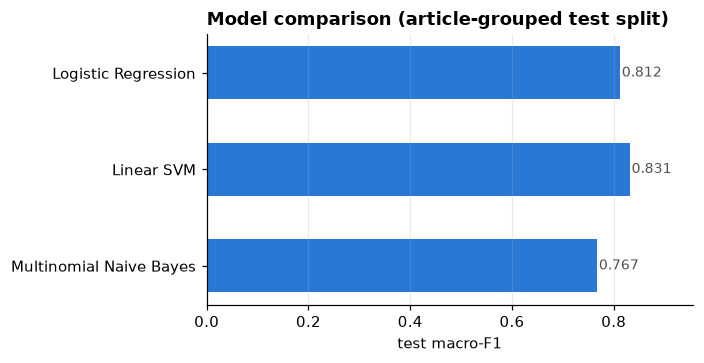

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
names = list(results)
vals = [results[n]["test macro-F1"] for n in names]
ax.barh(names[::-1], vals[::-1], color=BLUE, height=0.55)
for i, v in enumerate(vals[::-1]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, max(vals) * 1.15)
ax.set_xlabel("test macro-F1")
ax.set_title("Model comparison (article-grouped test split)", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 4. Best model — per-class report and confusion matrix

In [10]:
best = max(results, key=lambda n: results[n]["test macro-F1"])
print("Best model:", best, "\n")
print(classification_report(yte, results[best]["pred"], digits=3))

Best model: Linear SVM 

               precision    recall  f1-score   support

  agriculture      0.866     0.912     0.888       249
      economy      0.780     0.744     0.761       234
    education      0.866     0.884     0.875       242
entertainment      0.817     0.716     0.763       218
  environment      0.832     0.838     0.835       136
       health      0.833     0.867     0.850       241
     politics      0.735     0.765     0.750       247
     religion      0.861     0.912     0.886       217
     security      0.835     0.825     0.830       240
       sports      0.964     0.971     0.967       245
   technology      0.817     0.769     0.792       238
        world      0.773     0.776     0.775       237

     accuracy                          0.832      2744
    macro avg      0.832     0.832     0.831      2744
 weighted avg      0.832     0.832     0.832      2744



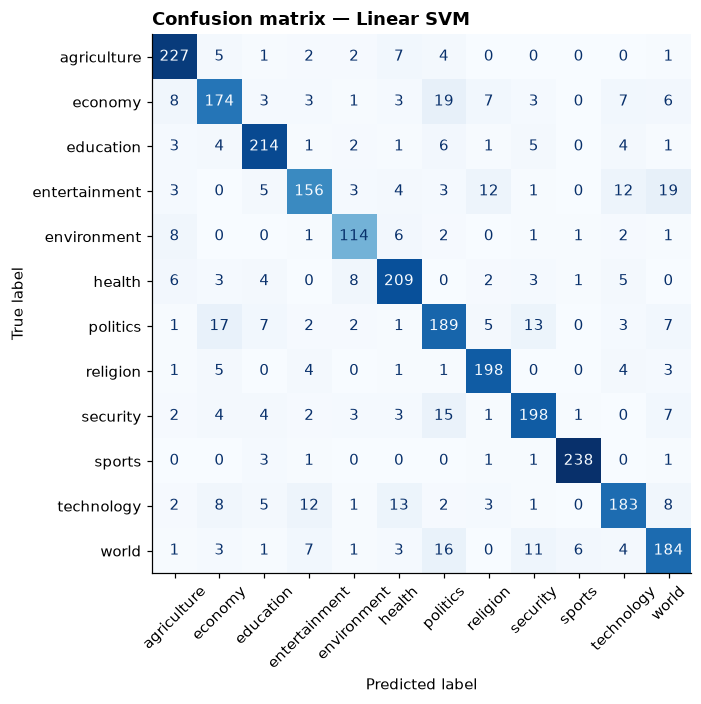

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay.from_predictions(
    yte, results[best]["pred"], xticks_rotation=45, cmap="Blues",
    colorbar=False, ax=ax, values_format="d")
ax.set_title(f"Confusion matrix — {best}", loc="left", fontweight="bold")
ax.grid(False)
plt.tight_layout(); plt.show()

## 5. Tuning — improving the best model

Two upgrades over the baseline setup:
- **Character n-grams (2–5) added to the word features.** Pashto is morphologically rich, and character n-grams capture stems and affixes that word tokens miss.
- **Grid over the SVM's `C`** with `class_weight="balanced"`, selected on the validation split.

In [12]:
from scipy.sparse import hstack

char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5),
                           max_features=200_000, sublinear_tf=True)
Xtr_c = char_vec.fit_transform(train["text"])
Xva_c = char_vec.transform(val["text"])
Xte_c = char_vec.transform(test["text"])

Xtr2, Xva2, Xte2 = hstack([Xtr, Xtr_c]), hstack([Xva, Xva_c]), hstack([Xte, Xte_c])
print("combined feature size:", Xtr2.shape[1])

best_C, best_val, best_model = None, 0, None
for C_ in [0.3, 0.5, 1.0, 2.0]:
    svm = LinearSVC(C=C_, class_weight="balanced")
    svm.fit(Xtr2, ytr)
    acc = accuracy_score(yva, svm.predict(Xva2))
    print(f"C={C_:<4} val acc {acc:.4f}")
    if acc > best_val:
        best_C, best_val, best_model = C_, acc, svm

pred_tuned = best_model.predict(Xte2)
tuned_acc = accuracy_score(yte, pred_tuned)
tuned_f1 = f1_score(yte, pred_tuned, average="macro")
print(f"\nTuned Linear SVM (C={best_C}, word+char TF-IDF, balanced weights)")
print(f"test acc {tuned_acc:.4f} | test macro-F1 {tuned_f1:.4f}")
print(f"baseline Linear SVM was: test acc {results['Linear SVM']['test acc']:.4f} "
      f"| macro-F1 {results['Linear SVM']['test macro-F1']:.4f}")

combined feature size: 320000


C=0.3  val acc 0.8477


C=0.5  val acc 0.8509


C=1.0  val acc 0.8535


C=2.0  val acc 0.8520

Tuned Linear SVM (C=1.0, word+char TF-IDF, balanced weights)
test acc 0.8502 | test macro-F1 0.8490
baseline Linear SVM was: test acc 0.8324 | macro-F1 0.8311


## 6. Conclusion

- All three classic algorithms perform far above the 8.3% random baseline — the dataset trains well out of the box.
- The tuned Linear SVM gives the strongest classic-ML result; sports, religion, security and agriculture are the easiest classes to recognize.
- Fine-tuning a multilingual transformer (XLM-R, mBERT) on the same stratified split is the natural next step and should push results considerably higher.

**Tips for reuse:** keep the fixed `random_state=42` stratified split for comparable results, and keep the text as-is — the authentic orthography is part of what makes this dataset realistic.